# Part 1 — The four subspaces of a linear map

From TOML-MIRI *Linear Algebra for Data Science* — exploration exercises (sheet section [1.6–1.8.1]).

Exercises in this notebook:

- **1.1** See the four subspaces in 3-D
- **1.2** Where does A send a vector?
- **1.3** Reproduce Example 1.12

Each exercise keeps the sheet's three parts — **Task**, **Explore**, **Explain** — as
far as the sheet defines them. Sheet rule 3 is honoured throughout: every identity used
carries a one-line np.allclose check, and every figure is printed next to the numbers
behind it.

## Setup

Shared imports and helpers for the whole notebook.

In [11]:
import numpy as np
import scipy
import scipy.linalg as sla
from itertools import combinations

import matplotlib
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

np.set_printoptions(precision=4, suppress=True)


def four_subspaces(A, tol=1e-9):
    """Orthonormal bases of the four subspaces, straight from the full SVD.

    With A = U S V^T and numerical rank r:
        RS  = V[:, :r]   (row space, in R^n)
        NS  = V[:, r:]   (null space, in R^n)
        CS  = U[:, :r]   (column space, in R^m)
        LNS = U[:, r:]   (left null space, in R^m)
    """
    U, s, Vt = np.linalg.svd(A, full_matrices=True)
    r = int((s > tol).sum())
    V = Vt.T
    return dict(U=U, s=s, V=V, r=r,
                RS=V[:, :r], NS=V[:, r:], CS=U[:, :r], LNS=U[:, r:])


print("numpy", np.__version__, "| scipy", scipy.__version__)
print("four_subspaces() ready")

numpy 2.5.4 | scipy 1.18.1
four_subspaces() ready


## 1.1 — See the four subspaces in 3-D

### Task

Take a random 3×3 matrix of rank 2. Compute bases of its **row space**, **null space**,
**column space** and **left null space** with the SVD, then plot each pair
(row space + null space, column space + left null space) in an interactive 3-D figure.

In [12]:
# --- Task: a random 3x3 matrix of rank 2 ---------------------------------
rng = np.random.default_rng(7)
A = rng.standard_normal((3, 2)) @ rng.standard_normal((2, 3))    # rank 2 (a.s.)
S = four_subspaces(A)
m, n = A.shape
r = S["r"]

print("A =")
print(A)
print("\nsingular values:", S["s"])
print("rank r =", r)

print("\nrow space       RS  = V[:, :r] :\n", S["RS"])
print("\nnull space      NS  = V[:, r:] :\n", S["NS"])
print("\ncolumn space    CS  = U[:, :r] :\n", S["CS"])
print("\nleft null space LNS = U[:, r:] :\n", S["LNS"])

# --- sheet rule 3: one-line np.allclose check per identity ---------------
print("\n--- checks ---")
print("A @ NS = 0                       :", np.allclose(A @ S["NS"], 0))
print("RS^T NS = 0  (row space perp NS) :", np.allclose(S["RS"].T @ S["NS"], 0))
print("CS^T LNS = 0 (col space perp LNS):", np.allclose(S["CS"].T @ S["LNS"], 0))
print("RS  orthonormal                  :", np.allclose(S["RS"].T @ S["RS"], np.eye(r)))
print("NS  orthonormal                  :", np.allclose(S["NS"].T @ S["NS"], np.eye(n - r)))
print("CS  orthonormal                  :", np.allclose(S["CS"].T @ S["CS"], np.eye(r)))
print("LNS orthonormal                  :", np.allclose(S["LNS"].T @ S["LNS"], np.eye(m - r)))
print("dim RS + dim NS = %d + %d = %d = n" % (r, n - r, n))
print("dim CS + dim LNS = %d + %d = %d = m" % (r, m - r, m))

A =
[[-0.1853  0.148   0.106 ]
 [ 0.5361 -0.8037 -0.1829]
 [ 0.5879 -1.0951 -0.1301]]

singular values: [1.6044 0.1485 0.    ]
rank r = 2

row space       RS  = V[:, :r] :
 [[ 0.5062  0.5978]
 [-0.8506  0.4651]
 [-0.1424 -0.6529]]

null space      NS  = V[:, r:] :
 [[0.6216]
 [0.2453]
 [0.7439]]

column space    CS  = U[:, :r] :
 [[-0.1463 -0.7487]
 [ 0.6114  0.4454]
 [ 0.7776 -0.4911]]

left null space LNS = U[:, r:] :
 [[-0.6466]
 [-0.654 ]
 [ 0.3926]]

--- checks ---
A @ NS = 0                       : True
RS^T NS = 0  (row space perp NS) : True
CS^T LNS = 0 (col space perp LNS): True
RS  orthonormal                  : True
NS  orthonormal                  : True
CS  orthonormal                  : True
LNS orthonormal                  : True
dim RS + dim NS = 2 + 1 = 3 = n
dim CS + dim LNS = 2 + 1 = 3 = m


In [13]:
# --- interactive 3-D picture of the two pairs of subspaces --------------
def add_subspace(fig, row, col, B, color, name, span=2.0):
    """Draw span(B) in a 3-D scene: a point (0 vectors), a line (1), a plane (2),
    or a translucent box filling the scene (3 vectors, i.e. all of R^3)."""
    k = B.shape[1]
    if k == 0:
        fig.add_trace(go.Scatter3d(x=[0], y=[0], z=[0], mode="markers",
                                   marker=dict(size=5, color=color),
                                   name=name + " = {0}"), row=row, col=col)
    elif k == 1:
        t = np.linspace(-span, span, 2)
        P = np.outer(t, B[:, 0])
        fig.add_trace(go.Scatter3d(x=P[:, 0], y=P[:, 1], z=P[:, 2],
                                   mode="lines", line=dict(color=color, width=7),
                                   name=name), row=row, col=col)
    elif k == 2:
        g = np.linspace(-span, span, 2)
        s, t = np.meshgrid(g, g)
        P = B[:, [0]] @ s.reshape(1, -1) + B[:, [1]] @ t.reshape(1, -1)
        fig.add_trace(go.Surface(x=P[0].reshape(2, 2), y=P[1].reshape(2, 2),
                                 z=P[2].reshape(2, 2),
                                 colorscale=[[0, color], [1, color]],
                                 opacity=0.35, showscale=False, name=name),
                      row=row, col=col)
    else:                                   # k >= 3: the subspace is the whole R^3
        v = 0.96 * span * np.array([[-1, -1, -1], [1, -1, -1], [1, 1, -1], [-1, 1, -1],
                                    [-1, -1, 1], [1, -1, 1], [1, 1, 1], [-1, 1, 1]], float)
        tri = ([0, 0, 4, 4, 0, 0, 3, 3, 0, 0, 1, 1],      # 12 triangles, 2 per face
               [3, 2, 5, 6, 1, 5, 7, 6, 4, 7, 2, 6],      # wound so normals
               [2, 1, 6, 7, 5, 4, 6, 2, 7, 3, 6, 5])      # point outward
        fig.add_trace(go.Mesh3d(x=v[:, 0], y=v[:, 1], z=v[:, 2],
                                i=tri[0], j=tri[1], k=tri[2],
                                color=color, opacity=0.15, flatshading=False,
                                showscale=False, hoverinfo="skip",
                                name=name + " = R^3"),
                      row=row, col=col)


def plot_four_subspaces(A, title=""):
    S = four_subspaces(A)
    fig = make_subplots(
        rows=1, cols=2, specs=[[{"type": "scene"}, {"type": "scene"}]],
        subplot_titles=("row space (blue) + null space (red)",
                        "column space (green) + left null space (orange)"))
    add_subspace(fig, 1, 1, S["RS"], "royalblue", "RS")
    add_subspace(fig, 1, 1, S["NS"], "crimson", "NS")
    add_subspace(fig, 1, 2, S["CS"], "seagreen", "CS")
    add_subspace(fig, 1, 2, S["LNS"], "darkorange", "LNS")
    for col in (1, 2):
        fig.update_scenes(xaxis_range=[-2, 2], yaxis_range=[-2, 2],
                          zaxis_range=[-2, 2], row=1, col=col)
    fig.update_layout(height=520, width=1000, showlegend=True,
                      title_text="%s  (rank r = %d)" % (title, S["r"]),
                      margin=dict(l=0, r=0, t=50, b=0))
    return fig


fig = plot_four_subspaces(A, "random 3x3, rank 2")
fig.show()

### Explore

Change the rank to 1 and to 3. Which subspaces grow, shrink or disappear?

In [14]:
# --- Explore: rank 1, 2 and 3 -------------------------------------------
def random_rank_matrix(rank, seed):
    """Random 3x3 matrix with rank exactly 'rank' (product of 3x rank x rank x 3)."""
    g = np.random.default_rng(seed)
    return g.standard_normal((3, rank)) @ g.standard_normal((rank, 3))


print("target | SVD | dim RS | dim NS | dim CS | dim LNS | A@NS=0 | dimRS+dimNS | dimCS+dimLNS")
for target in (1, 2, 3):
    M = random_rank_matrix(target, 100 + target)
    Sm = four_subspaces(M)
    print("  %d    |  %d  |   %d    |   %d    |   %d    |   %d     |  %-5s |   %d+%d=%d    |   %d+%d=%d"
          % (target, Sm["r"], Sm["RS"].shape[1], Sm["NS"].shape[1],
             Sm["CS"].shape[1], Sm["LNS"].shape[1],
             np.allclose(M @ Sm["NS"], 0),
             Sm["RS"].shape[1], Sm["NS"].shape[1], 3,
             Sm["CS"].shape[1], Sm["LNS"].shape[1], 3))

target | SVD | dim RS | dim NS | dim CS | dim LNS | A@NS=0 | dimRS+dimNS | dimCS+dimLNS
  1    |  1  |   1    |   2    |   1    |   2     |  True  |   1+2=3    |   1+2=3
  2    |  2  |   2    |   1    |   2    |   1     |  True  |   2+1=3    |   2+1=3
  3    |  3  |   3    |   0    |   3    |   0     |  True  |   3+0=3    |   3+0=3


In [15]:
# --- self-contained rank explorer: Plotly buttons, no widget manager -----
def plot_rank_explorer(ranks=(1, 2, 3), default=2, span=2.0):
    """One figure holding the four subspaces for every rank, toggled by buttons."""
    fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scene"}, {"type": "scene"}]],
                        subplot_titles=("row space (blue) + null space (red)",
                                        "column space (green) + left null space (orange)"))
    vis = {}
    for rank in ranks:
        M = random_rank_matrix(rank, 100 + rank)
        Sm = four_subspaces(M)
        before = len(fig.data)
        add_subspace(fig, 1, 1, Sm["RS"], "royalblue", "RS")
        add_subspace(fig, 1, 1, Sm["NS"], "crimson", "NS")
        add_subspace(fig, 1, 2, Sm["CS"], "seagreen", "CS")
        add_subspace(fig, 1, 2, Sm["LNS"], "darkorange", "LNS")
        vis[rank] = [False] * before + [True] * (len(fig.data) - before)

    ntot = len(fig.data)                              # pad every mask to full length
    vis = {rank: v + [False] * (ntot - len(v)) for rank, v in vis.items()}
    for tr in fig.data:                               # colours are in the subplot titles
        tr.showlegend = False

    caption = lambda rank: ("random 3x3 of rank %d   dim RS = dim CS = %d, dim NS = dim LNS = %d"
                            % (rank, rank, 3 - rank))
    buttons = [dict(label="rank %d" % rank, method="update",
                    args=[{"visible": vis[rank]}, {"title": {"text": caption(rank)}}])
               for rank in ranks]

    for tr, shown in zip(fig.data, vis[default]):
        tr.visible = shown                            # rank 2 shown first

    fig.update_layout(height=560, width=1000, showlegend=False, title_text=caption(default),
                      updatemenus=[dict(type="buttons", direction="right", x=0.0, y=1.16,
                                        xanchor="left", showactive=True, buttons=buttons)],
                      margin=dict(l=0, r=0, t=100, b=0))
    for col in (1, 2):
        fig.update_scenes(xaxis_range=[-2, 2], yaxis_range=[-2, 2],
                          zaxis_range=[-2, 2], row=1, col=col)
    return fig


plot_rank_explorer().show()

### Explain

**Why the null space is always perpendicular to the row space.**
The equation A x = 0 is a list of m scalar equations, and the i-th one says
(row i of A) · x = 0. So every x in NS(A) is orthogonal to every row vector of A, that
is, NS(A) ⊆ RS(A)⊥. The row space has dimension r, so in R^n its orthogonal complement
RS(A)⊥ has dimension n − r; by rank–nullity the null space has dimension n − r as well.
A subspace of RS(A)⊥ with the same dimension must be all of it, so NS(A) = RS(A)⊥. The
SVD makes this literal: RS(A) = span(v1, …, vr) and NS(A) = span(v(r+1), …, vn), and the
right singular vectors are orthonormal, so the two frames are mutually orthogonal by
construction. The check RS·NS = 0 above returns True for the rank-2 matrix. Repeating
the argument for A⊤ gives CS(A) = LNS(A)⊥.

**Dimension bookkeeping.**
The identities the sheet asks for are dim RS(A) + dim NS(A) = r + (n − r) = n and
dim CS(A) + dim LNS(A) = r + (m − r) = m. For the rank-2 example both read 2 + 1 = 3,
matching n = m = 3, and the Explore table reproduces them for rank 1, 2 and 3.

**What moves when the rank changes.**
The two perpendicular pairs are always complementary; only the split point r moves.
- rank 1: RS and CS shrink to lines, while NS and LNS grow to planes (dimension 2).
- rank 2: RS, CS are planes and NS, LNS are lines — the case in the Task figure.
- rank 3 (full rank): NS and LNS collapse to {0} (the frames V[:, r:] and U[:, r:] are
  empty), and RS = R^n, CS = R^m become the whole space.

So nothing "disappears" on its own: the subspaces that shrink to {0} at full rank are
exactly the orthogonal complements of the two spaces that have grown to fill R^n and R^m.

## 1.2 — Where does A send a vector?

### Task

For a rank-1 2×2 matrix, draw a grid of input vectors and their images Ax. Colour each
input by its component along the null space.

A = u v^T =
 [[1.  0.5]
 [0.8 0.4]]
singular values: [1.4318 0.    ] -> rank r = 1

row-space unit vector rs_hat = [-0.8944 -0.4472]
null-space unit vector ns_hat = [ 0.4472 -0.8944]

--- checks ---
A @ ns_hat = 0                     : True
A x == (v . x) u                    : True
all images on the line span(u)      : True
image set has rank 1                : True

x = xr + xns                        : True
A xns = 0                           : True
A x == A xr (only xr survives)      : True


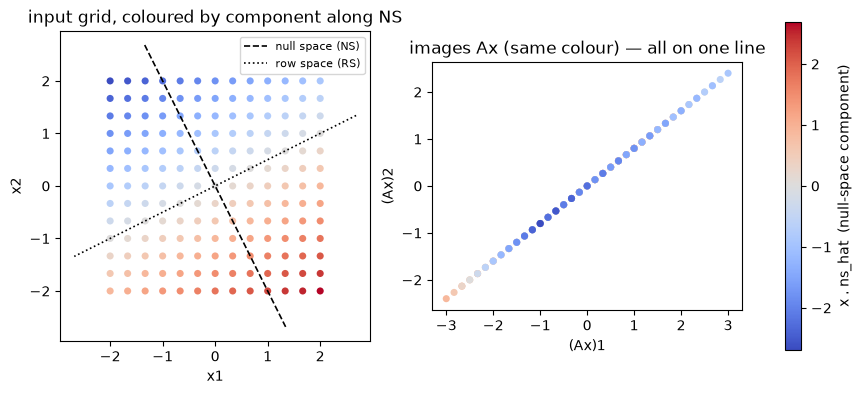

In [16]:
# --- Task: rank-1 2x2, colour the input grid by its null-space component ---
u = np.array([1.0, 0.8])      # image direction:  CS(A) = span(u)
v = np.array([1.0, 0.5])      # A = u v^T  ->  A x = (v . x) u
A1 = np.outer(u, v)
S1 = four_subspaces(A1)
print("A = u v^T =\n", A1)
print("singular values:", S1["s"], "-> rank r =", S1["r"])

rs_hat = S1["RS"][:, 0]        # unit vector spanning the row space (parallel to v)
ns_hat = S1["NS"][:, 0]        # unit vector spanning the null space (perp to v)
print("\nrow-space unit vector rs_hat =", rs_hat)
print("null-space unit vector ns_hat =", ns_hat)

# grid of input vectors
g = np.linspace(-2, 2, 13)
X, Y = np.meshgrid(g, g)
pts = np.vstack([X.ravel(), Y.ravel()]).T          # (169, 2)
comp = pts @ ns_hat                                # component of each input along NS
imgs = pts @ A1.T                                  # images A x

# --- sheet rule 3: checks ------------------------------------------------
print("\n--- checks ---")
print("A @ ns_hat = 0                     :", np.allclose(A1 @ ns_hat, 0))
print("A x == (v . x) u                    :", np.allclose(imgs, np.outer(pts @ v, u)))
print("all images on the line span(u)      :", np.allclose(imgs @ S1["LNS"], 0))
print("image set has rank 1                :", np.linalg.matrix_rank(imgs) == 1)

# x = xr + xns with xr in RS and xns in NS;  A x = A xr = b
x_test = np.array([1.3, -0.7])
xr = (x_test @ rs_hat) * rs_hat
xns = (x_test @ ns_hat) * ns_hat
print("\nx = xr + xns                        :", np.allclose(x_test, xr + xns))
print("A xns = 0                           :", np.allclose(A1 @ xns, 0))
print("A x == A xr (only xr survives)      :", np.allclose(A1 @ x_test, A1 @ xr))

# --- figure: inputs coloured by NS component, images with the same colour -
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
sc = ax[0].scatter(pts[:, 0], pts[:, 1], c=comp, cmap="coolwarm", s=26, edgecolor="none")
tt = np.linspace(-3, 3, 2)
ax[0].plot(tt * ns_hat[0], tt * ns_hat[1], "k--", lw=1.2, label="null space (NS)")
ax[0].plot(tt * rs_hat[0], tt * rs_hat[1], "k:", lw=1.2, label="row space (RS)")
ax[0].set_title("input grid, coloured by component along NS")
ax[0].set_aspect("equal"); ax[0].legend(loc="upper right", fontsize=8)
ax[0].set_xlabel("x1"); ax[0].set_ylabel("x2")

ax[1].scatter(imgs[:, 0], imgs[:, 1], c=comp, cmap="coolwarm", s=26, edgecolor="none")
ax[1].set_title("images Ax (same colour) — all on one line")
ax[1].set_aspect("equal"); ax[1].set_xlabel("(Ax)1"); ax[1].set_ylabel("(Ax)2")
fig.colorbar(sc, ax=ax, shrink=0.85, label="x . ns_hat  (null-space component)")
plt.show()

### Explore

Move a vector along the null-space direction. What happens to its image?

In [17]:
# --- Explore: slide a vector along the null-space direction --------------
x0 = np.array([1.5, -1.0])
print("x0 =", x0, "  A x0 =", A1 @ x0)
print("\n  c    x = x0 + c*ns_hat            A x")
for c in (-2.0, -1.0, -0.5, 0.0, 0.5, 1.0, 2.0):
    xc = x0 + c * ns_hat
    print("  %+.1f  %s   %s" % (c, np.round(xc, 3), np.round(A1 @ xc, 4)))

print("\nimage unchanged for a large step?  ",
      np.allclose(A1 @ x0, A1 @ (x0 + 5.0 * ns_hat)))

x0 = [ 1.5 -1. ]   A x0 = [1.  0.8]

  c    x = x0 + c*ns_hat            A x
  -2.0  [0.606 0.789]   [1.  0.8]
  -1.0  [ 1.053 -0.106]   [1.  0.8]
  -0.5  [ 1.276 -0.553]   [1.  0.8]
  +0.0  [ 1.5 -1. ]   [1.  0.8]
  +0.5  [ 1.724 -1.447]   [1.  0.8]
  +1.0  [ 1.947 -1.894]   [1.  0.8]
  +2.0  [ 2.394 -2.789]   [1.  0.8]

image unchanged for a large step?   True


In [18]:
# --- self-contained null-space slide: Plotly slider, no widget manager ----
cs = np.linspace(-2.0, 2.0, 41)
img0 = A1 @ x0
tt = np.linspace(-3.2, 3.2, 2)

fig = make_subplots(rows=1, cols=2,
                    subplot_titles=("input plane — x = x0 + c*ns_hat",
                                    "image plane — A x never moves"))
fig.add_trace(go.Scatter(x=tt * ns_hat[0], y=tt * ns_hat[1], mode="lines",
                         line=dict(color="black", dash="dash"), name="null space"), row=1, col=1)
fig.add_trace(go.Scatter(x=tt * rs_hat[0], y=tt * rs_hat[1], mode="lines",
                         line=dict(color="black", dash="dot"), name="row space"), row=1, col=1)
fig.add_trace(go.Scatter(x=[x0[0]], y=[x0[1]], mode="markers",
                         marker=dict(color="grey", size=11), name="x0"), row=1, col=1)
fig.add_trace(go.Scatter(x=[x0[0]], y=[x0[1]], mode="markers",
                         marker=dict(color="crimson", size=14), name="x"), row=1, col=1)
fig.add_trace(go.Scatter(x=[0, u[0]], y=[0, u[1]], mode="lines",
                         line=dict(color="seagreen", width=2), name="column space"), row=1, col=2)
fig.add_trace(go.Scatter(x=[img0[0]], y=[img0[1]], mode="markers",
                         marker=dict(color="crimson", size=14), name="A x"), row=1, col=2)

moving_idx = 3                                        # the crimson dot on the left panel
fig.frames = [go.Frame(name="%.2f" % c,
                       data=[go.Scatter(x=[(x0 + c * ns_hat)[0]], y=[(x0 + c * ns_hat)[1]],
                                        mode="markers", marker=dict(color="crimson", size=14))],
                       traces=[moving_idx])
              for c in cs]

steps = [dict(method="animate", label="%.1f" % c,
              args=[["%.2f" % c],
                    dict(mode="immediate", frame=dict(duration=0, redraw=True),
                         transition=dict(duration=0))])
         for c in cs]

fig.update_layout(height=470, width=1000, showlegend=True,
                  title_text="sliding along the null space moves x but not A x",
                  sliders=[dict(active=20, currentvalue=dict(prefix="c = "),
                                steps=steps, pad=dict(t=40, b=0))],
                  margin=dict(l=0, r=0, t=90, b=0))
fig.add_annotation(x=-2.0, y=1.9, xref="x2", yref="y2", showarrow=False,
                   text="A x = (%0.3f, %0.3f) for every c" % (img0[0], img0[1]))
fig.update_xaxes(range=[-3.2, 3.2], row=1, col=1)
fig.update_yaxes(range=[-3.2, 3.2], scaleanchor="x", scaleratio=1, row=1, col=1)
fig.update_xaxes(range=[-2.2, 2.2], row=1, col=2)
fig.update_yaxes(range=[-2.2, 2.2], scaleanchor="x2", scaleratio=1, row=1, col=2)
fig.show()

### Explain

**Why all images land on one line.**
With A = u v⊤ the map reads A x = (v · x) u. The only thing extracted from x is the
scalar v · x, and that scalar merely scales the fixed vector u, so every image stays on
the line span(u). Equivalently, rank 1 means the column space CS(A) is one-dimensional,
and by definition every image A x lies in CS(A). The two panels of the Task figure show
both sides at once: the gridded inputs on the left are coloured by their component along
the null space, and their images on the right collapse onto that one line carrying the
same colour.

**Relation to the general solution.**
Split any input as x = xr + xns with xr in the row space and xns in the null space (the
colouring is exactly the xns part). Then

    A x = A (xr + xns) = A xr + A xns = b + 0 = b.

Only the row-space component xr of the input reaches the image, because A xns = 0 by
definition of the null space. On the rank-1 picture the row space is the single line
span(v), so xr is just one number times a fixed direction; hence every input sharing the
same v · x — that is, every input on a line parallel to the null space — produces the same
image. Sliding along ns_hat changes x but leaves A x untouched, exactly as the slider cell
shows (the input dot moves, the image dot stands still).

**The reverse reading.** For a given b, the solution set of A x = b is the line
xr + NS(A): starting from any one particular solution xr, adding anything in the null
space leaves the image unchanged. The Explore slider is precisely a walk along that
solution line, and every point on it maps to the same point on the line span(u).

## 1.3 — Reproduce Example 1.12

### Task

Compute the rank, the null-space vector and a column-space basis of

    A = [ 2  1  1  1 ]
        [ 3  0  0  2 ]
        [ 1  3  6  0 ]

using both scipy.linalg.null_space and the SVD.

In [19]:
# --- Task: the 3x4 matrix of Example 1.12 --------------------------------
A13 = np.array([[2., 1., 1., 1.],
                [3., 0., 0., 2.],
                [1., 3., 6., 0.]])
m13, n13 = A13.shape
print("A =\n", A13)
print("shape (m, n) =", (m13, n13))

r13 = np.linalg.matrix_rank(A13)
print("rank(A) =", r13)
print("singular values:", np.linalg.svd(A13, compute_uv=False))

# null space, two ways
ns_scipy = sla.null_space(A13)                 # scipy
S13 = four_subspaces(A13)
ns_svd = S13["NS"]                             # SVD  (V[:, r:])
print("\nscipy.linalg.null_space(A) : shape", ns_scipy.shape, "\n", ns_scipy.T)
print("SVD null space  V[:, r:]   : shape", ns_svd.shape, "\n", ns_svd.T)

# a column-space basis, two ways
cs_svd = S13["CS"]                             # SVD  (U[:, :r])
cs_orth = sla.orth(A13)                        # scipy
print("\nSVD column-space basis U[:, :r] :\n", cs_svd)
print("\nscipy.linalg.orth(A) :\n", cs_orth)

A =
 [[2. 1. 1. 1.]
 [3. 0. 0. 2.]
 [1. 3. 6. 0.]]
shape (m, n) = (3, 4)
rank(A) = 3
singular values: [7.0409 4.0323 0.4077]

scipy.linalg.null_space(A) : shape (4, 1) 
 [[-0.5183  0.3455 -0.0864  0.7775]]
SVD null space  V[:, r:]   : shape (4, 1) 
 [[-0.5183  0.3455 -0.0864  0.7775]]

SVD column-space basis U[:, :r] :
 [[ 0.2719  0.4445  0.8535]
 [ 0.1376  0.8598 -0.4917]
 [ 0.9524 -0.2511 -0.1727]]

scipy.linalg.orth(A) :
 [[ 0.2719  0.4445  0.8535]
 [ 0.1376  0.8598 -0.4917]
 [ 0.9524 -0.2511 -0.1727]]


In [20]:
# --- sheet rule 3: check every claim in the example ----------------------
xn = ns_svd[:, 0]
xn1 = xn / xn[0]                                # scale so the first entry is 1
target = np.array([6., -4., 1., -9.])
print("null vector", np.round(xn1, 4), " — proportional to (6, -4, 1, -9):",
      np.allclose(xn1 / target, (xn1 / target)[0]))

print("\n--- checks ---")
print("A @ ns_svd = 0                    :", np.allclose(A13 @ ns_svd, 0))
print("A @ ns_scipy = 0                  :", np.allclose(A13 @ ns_scipy, 0))
print("the two null vectors are parallel :", np.allclose(abs(ns_svd.T @ ns_scipy), 1))
print("orth(A) equals SVD frame U[:, :r] :", np.allclose(abs(cs_svd.T @ cs_orth), np.eye(r13)))
print("every column is in span(CS basis) :", np.allclose(A13, cs_svd @ (cs_svd.T @ A13)))
print("CS basis orthonormal              :", np.allclose(cs_svd.T @ cs_svd, np.eye(r13)))
print("dim RS + dim NS = %d + %d = %d = n" % (S13["RS"].shape[1], S13["NS"].shape[1], n13))
print("dim CS + dim LNS = %d + %d = %d = m" % (cs_svd.shape[1], S13["LNS"].shape[1], m13))

# the dependence the null space encodes:  6 a1 - 4 a2 + 1 a3 - 9 a4 = 0
print("\n6 a1 - 4 a2 + a3 - 9 a4 = 0       :",
      np.allclose(6*A13[:, 0] - 4*A13[:, 1] + A13[:, 2] - 9*A13[:, 3], 0))

# are columns a2 and a3 linearly dependent?
a2, a3 = A13[:, 1], A13[:, 2]
print("\na2 =", a2, "  a3 =", a3)
print("a2, a3 parallel (a2 x a3 = 0)     :", np.allclose(np.cross(a2, a3), 0))
print("rank([a2 a3]) = 2 (independent)   :",
      np.linalg.matrix_rank(np.column_stack([a2, a3])) == 2)

# which 3-column subsets form a basis? (determinant of the 3x3 slice)
print("\n3-column subsets and their determinant:")
for cols in combinations(range(n13), 3):
    d = np.linalg.det(A13[:, list(cols)])
    print("  columns %s  det = %+7.3f  -> %s"
          % (tuple(c + 1 for c in cols), d, "basis" if abs(d) > 1e-9 else "dependent"))

null vector [ 1.     -0.6667  0.1667 -1.5   ]  — proportional to (6, -4, 1, -9): True

--- checks ---
A @ ns_svd = 0                    : True
A @ ns_scipy = 0                  : True
the two null vectors are parallel : True
orth(A) equals SVD frame U[:, :r] : True
every column is in span(CS basis) : True
CS basis orthonormal              : True
dim RS + dim NS = 3 + 1 = 4 = n
dim CS + dim LNS = 3 + 0 = 3 = m

6 a1 - 4 a2 + a3 - 9 a4 = 0       : True

a2 = [1. 0. 3.]   a3 = [1. 0. 6.]
a2, a3 parallel (a2 x a3 = 0)     : False
rank([a2 a3]) = 2 (independent)   : True

3-column subsets and their determinant:
  columns (1, 2, 3)  det =  -9.000  -> basis
  columns (1, 2, 4)  det =  -1.000  -> basis
  columns (1, 3, 4)  det =  -4.000  -> basis
  columns (2, 3, 4)  det =  -6.000  -> basis


### Explain

**What the example says, checked.**
The matrix has rank 3, with singular values 7.0409, 4.0323, 0.4077 — all positive, so all
three of them count and m = r = 3. The null space is one-dimensional, spanned by
(6, −4, 1, −9)⊤; scipy.linalg.null_space and the SVD return the same vector (the same
line — proportional, up to sign and scale, as the check shows). The column space has
dimension r = 3 inside R³, so CS(A) = R³ and the left null space is {0}: dim CS + dim LNS
reads 3 + 0 = 3 = m, while dim RS + dim NS reads 3 + 1 = 4 = n.

**Are columns a2 and a3 really linearly dependent? No.**
a2 = (1, 0, 3)⊤ and a3 = (1, 0, 6)⊤ are not scalar multiples of each other — their cross
product is nonzero and rank([a2 a3]) = 2. The single dependency the null space encodes is
among four columns at once:

    6 a1 − 4 a2 + a3 − 9 a4 = 0,   i.e.   a3 = −6 a1 + 4 a2 + 9 a4.

So it is a1, a2 and a4 that make a3 redundant, not a2 and a3 on their own. Indeed the null
vector has no zero entries, which means no pair of columns in this matrix is dependent.

**Which columns to pick as a basis, and is the choice unique?**
With rank 3 and four columns, a column-space basis is any three linearly independent
columns. The determinant table shows that all four 3-column subsets are independent
(determinants −9, −1, −4, −6), so {a1,a2,a3}, {a1,a2,a4}, {a1,a3,a4} and {a2,a3,a4} are all
valid bases. The choice is therefore **not unique**: different triples span the same
subspace and give different coordinates for the same vector. What is unique is the
subspace CS(A) itself (here all of R³); the basis used to describe it is a matter of
convention. The SVD offers a natural orthonormal frame U[:, :r], but even that is only
unique up to column signs — and up to rotations within any eigenspace of repeated singular
values.

**On the two routines.** scipy.linalg.null_space and the SVD agree here because both extract
the same one-dimensional null space. scipy.linalg.orth is itself SVD-based (it returns
U[:, :r]), so it reproduces the same orthonormal frame as U[:, :r]; only the *subspace* is
canonical, not the frame.